# Classification experiments: results

Executed companion to [`docs/classification.md`](../docs/classification.md) (Part B), which explains every step. The notebook trains nothing: it reads the saved results in `outputs/classification/experiments/` (written by `src/classification/run_experiments.py`) and redraws the figures. The frozen v1 forest (test PR-AUC 0.375, recall in the top 20% 0.532) is the headline result.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from classification.experiments import EXP_DIR, TABLES_DIR, FIGURES_DIR, V1_DIR
from classification import experiment_figures
pd.set_option('display.max_colwidth', 80); pd.set_option('display.precision', 4)
t = lambda n: pd.read_csv(TABLES_DIR / f'{n}.csv')
fig = lambda n: display(Image(filename=str(FIGURES_DIR / f'{n}.png')))
experiment_figures.make_all()   # redraw every figure from the saved tables

## 1. Train / validation / test split

Five expanding-window folds validate on Jan–May 2018; each trains on orders with T from Jan 2017 up to the fold's cut-off minus a 27-day purge gap. The test window is Jun–Aug 2018.

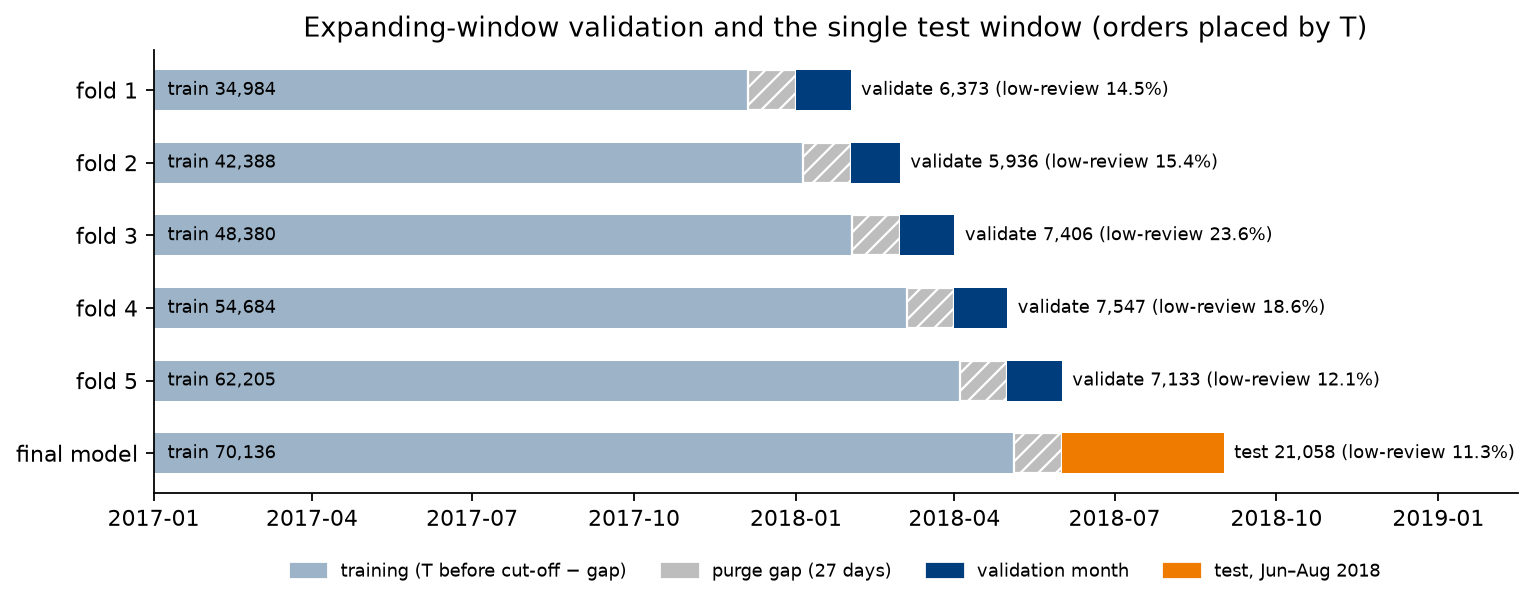

,fold,training T from,training T to (last order),scored window,training orders,scored orders,training low-review rate,scored low-review rate,training labels answered after cut-off
0,fold1,2017-01-11,2017-12-04,2018-01-01 to 2018-01-31,34984,6373,0.1209,0.1455,0.0024
1,fold2,2017-01-11,2018-01-04,2018-02-01 to 2018-02-28,42388,5936,0.1330,0.1541,0.0017
2,fold3,2017-01-11,2018-02-01,2018-03-01 to 2018-03-31,48380,7406,0.1336,0.2356,0.0017
3,fold4,2017-01-11,2018-03-04,2018-04-01 to 2018-04-30,54684,7547,0.1363,0.1862,0.0016
4,fold5,2017-01-11,2018-04-03,2018-05-01 to 2018-05-31,62205,7133,0.1487,0.1207,0.0015
5,final,2017-01-11,2018-05-04,2018-06-01 to 2018-08-31,70136,21058,0.1513,0.1126,0.0012


In [2]:
fig('E01_split_timeline')
pd.read_csv(V1_DIR / 'tables' / 'fold_table.csv')

## 2. Processing pipeline (fitted inside every fold)

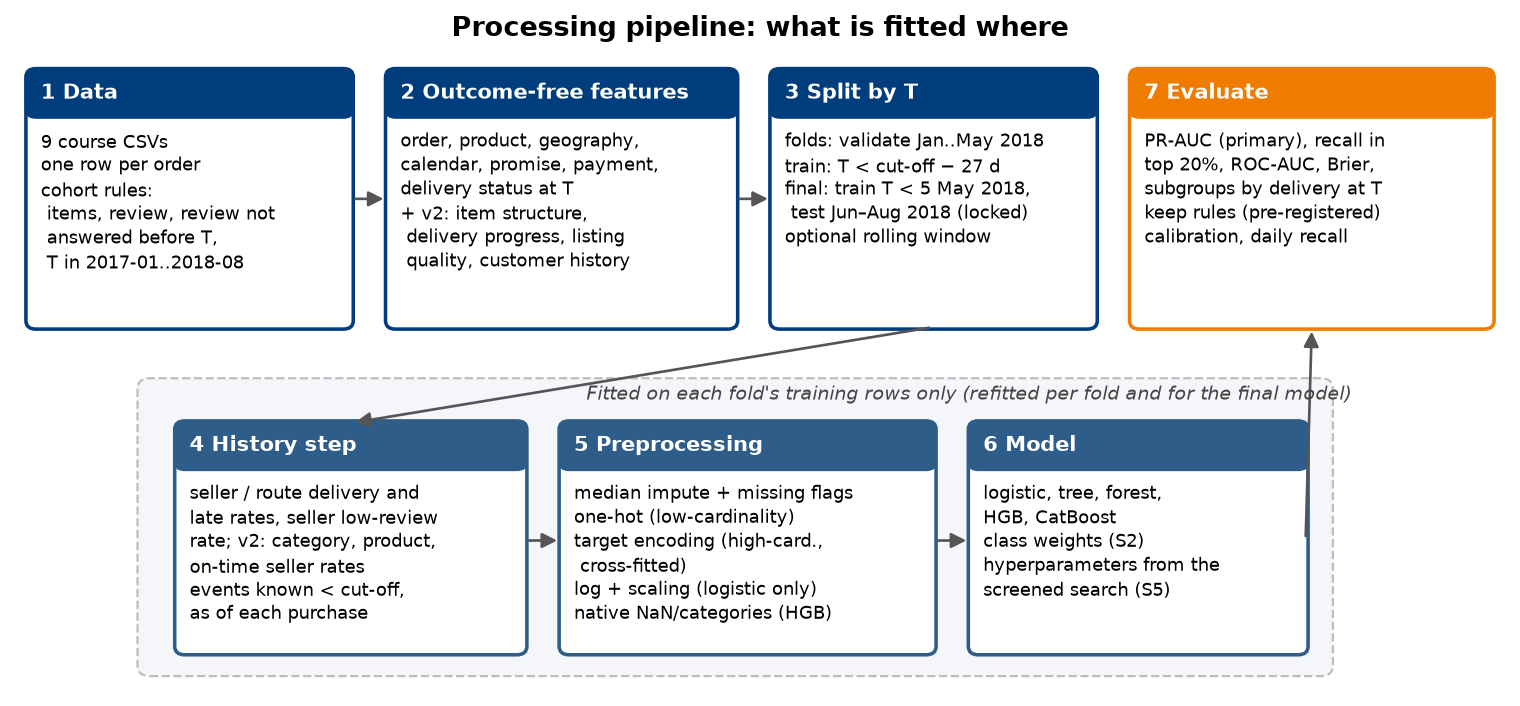

In [3]:
fig('E02_pipeline')

## 3. Experiments and their effect

Each row changes one thing against the step's reference; `decision` applies the agreed rule. Dots in the chart are the five monthly differences. The test columns were added after every decision was frozen and are a secondary reference only.

In [4]:
led = t('ledger')
led[['step','experiment','mean_val_pr_auc','d_pr_auc','months_better','d_recall','d_roc_auc','d_brier','d_pr_delivered','train_minus_val_pr_auc','decision','test_pr_auc','d_test_pr_auc']]

,step,experiment,mean_val_pr_auc,d_pr_auc,months_better,d_recall,d_roc_auc,d_brier,d_pr_delivered,train_minus_val_pr_auc,decision,test_pr_auc,d_test_pr_auc
0,S0,"v1 frozen forest, reproduced",0.5463,NaN,NaN,NaN,NaN,NaN,NaN,0.0209,reference,0.3749,NaN
1,S1a,lateness by calendar day,0.5461,-1.9355e-04,2.0,8.2829e-04,-0.0006,2.6865e-05,0.0001,0.0209,adopted (audit),0.3757,7.7754e-04
2,S1b,drop labels answered after cut-off,0.5457,-3.4975e-04,3.0,6.8817e-04,-0.0010,-7.2683e-05,-0.0002,0.0224,reported only,0.3752,-5.1330e-04
3,S2,forest: class weight none,0.5468,6.7235e-04,3.0,7.3441e-04,0.0007,-5.6942e-02,0.0007,0.0112,keep,0.3750,-7.4992e-04
4,S2,forest: class weight 2:1,0.5458,-3.2548e-04,2.0,-1.0943e-03,0.0004,-5.2034e-02,0.0006,0.0182,keep,0.3762,5.2371e-04
5,S2,logistic: class weight balanced (reference),0.5299,NaN,NaN,NaN,NaN,NaN,NaN,-0.0567,reference,0.3668,NaN
6,S2,logistic: class weight none,0.5352,5.3395e-03,5.0,1.4195e-03,0.0003,-7.7088e-02,0.0014,-0.0594,keep,0.3689,2.0715e-03
7,S2,logistic: class weight 2:1,0.5332,3.3644e-03,5.0,3.2207e-04,0.0003,-7.2253e-02,0.0011,-0.0579,keep,0.3687,1.9277e-03
8,S3,+ item_structure,0.5467,-3.2091e-05,1.0,-1.3893e-03,0.0001,3.5903e-05,-0.0013,0.0118,reject,0.3751,1.5828e-04
9,S3,+ delivery_progress,0.5472,4.2960e-04,4.0,-1.7474e-03,-0.0002,-8.2316e-06,0.0001,0.0110,reject,0.3742,-7.9986e-04


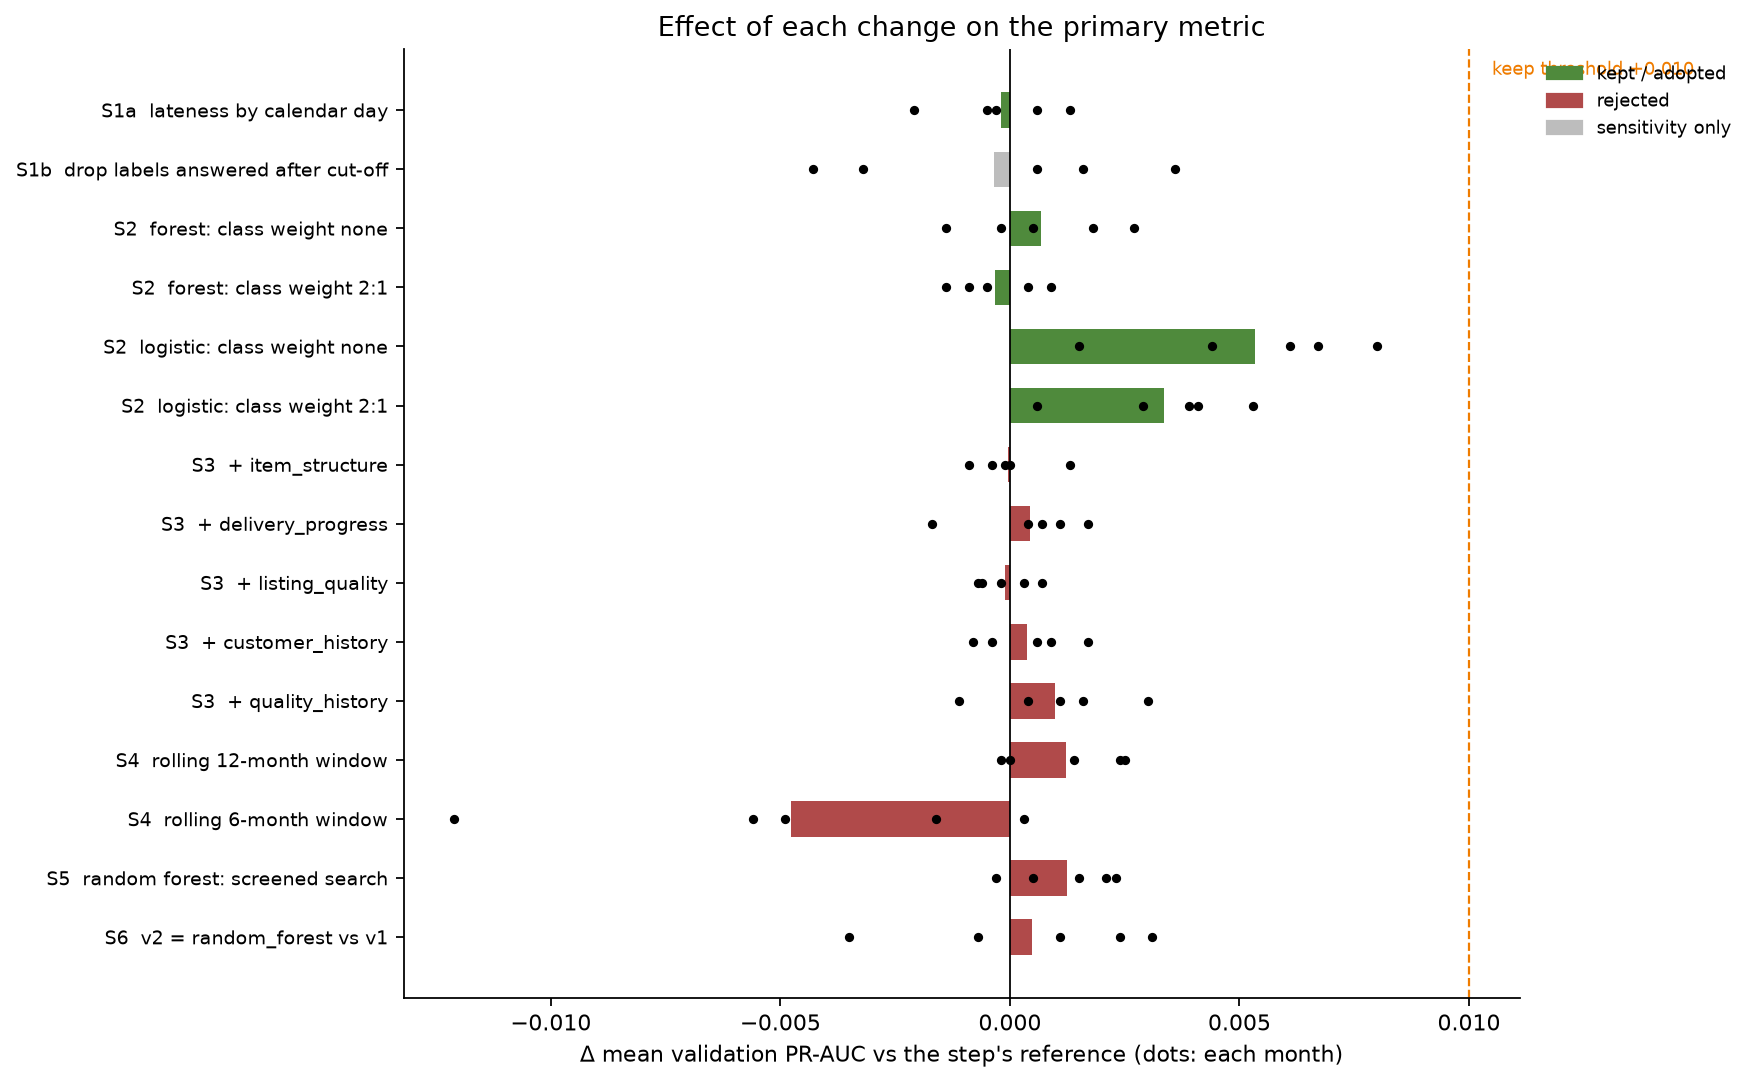

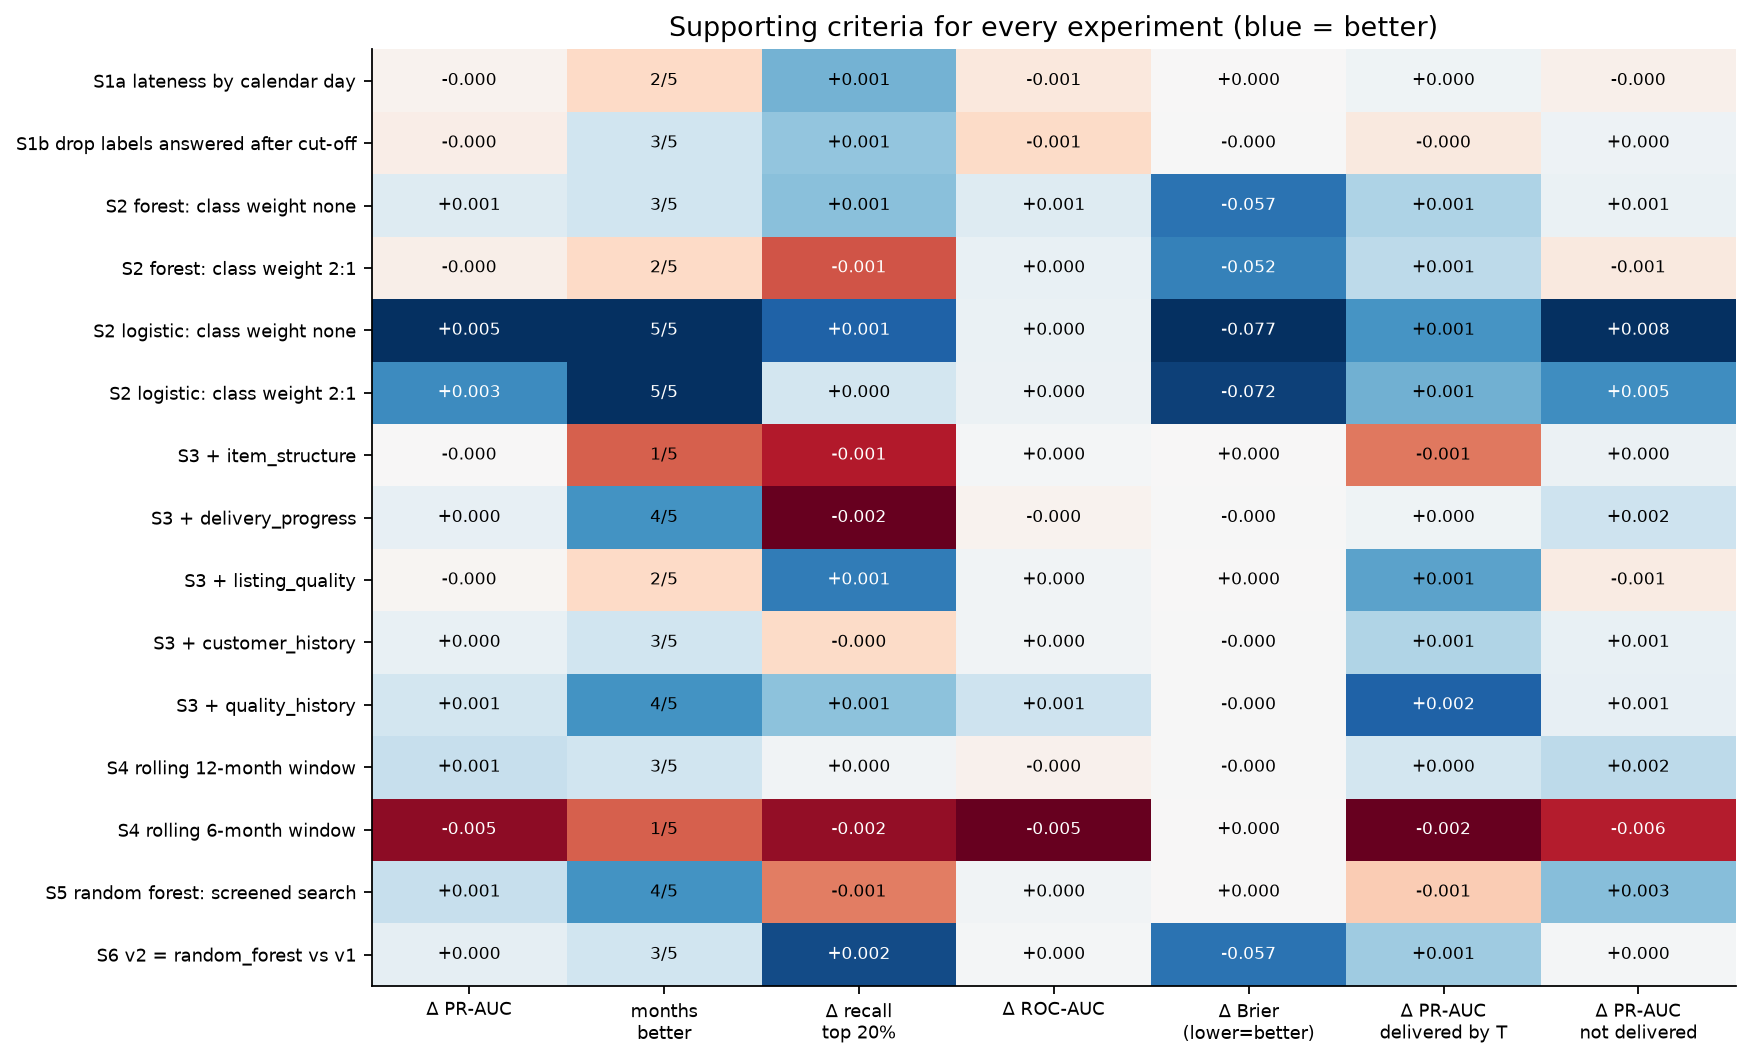

In [5]:
fig('E03_ablation'); fig('E04_supporting_criteria')

## 4. Class balancing

Every family at its tuned hyperparameters with no correction, class weights (balanced, 2:1), random undersampling, random oversampling and SMOTE. The reference is balanced weights; `passes_rule` = Brier lower in ≥ 4/5 months with PR-AUC not lower by more than 0.005. Test columns are a secondary evaluation.

In [6]:
cb = t('class_balance')
cb[['type','family','strategy','train_pr_auc_cv','val_pr_auc','val_brier','val_mean_score','val_recall_at_capacity','test_pr_auc','test_brier','test_recall_at_capacity','passes_rule','chosen_by_rule']]

,type,family,strategy,train_pr_auc_cv,val_pr_auc,val_brier,val_mean_score,val_recall_at_capacity,test_pr_auc,test_brier,test_recall_at_capacity,passes_rule,chosen_by_rule
0,ensemble (bagging),random_forest,none,0.5579,0.5468,0.1005,0.1631,0.5950,0.3750,0.0883,0.5335,True,True
1,ensemble (bagging),random_forest,balanced weights,0.5670,0.5461,0.1574,0.4024,0.5942,0.3757,0.1494,0.5348,True,False
2,ensemble (bagging),random_forest,2:1 weights,0.5640,0.5458,0.1054,0.2405,0.5931,0.3762,0.1009,0.5356,True,False
3,ensemble (bagging),random_forest,random undersampling,0.5053,0.5330,0.1779,0.4406,0.5859,0.3659,0.1638,0.5276,False,False
4,ensemble (bagging),random_forest,random oversampling,0.6320,0.5415,0.1589,0.4037,0.5900,0.3712,0.1505,0.5323,False,False
5,ensemble (bagging),random_forest,SMOTE,0.5399,0.5341,0.1061,0.2341,0.5811,0.3594,0.0996,0.5217,False,False
6,ensemble (boosting),hist_gb,none,0.5565,0.5454,0.1008,0.1605,0.5912,0.3712,0.0879,0.5361,True,True
7,ensemble (boosting),hist_gb,balanced weights,0.5290,0.5458,0.1717,0.4292,0.5904,0.3717,0.1606,0.5335,True,False
8,ensemble (boosting),hist_gb,2:1 weights,0.5514,0.5440,0.1058,0.2406,0.5880,0.3733,0.0999,0.5331,True,False
9,ensemble (boosting),hist_gb,random undersampling,0.5056,0.5376,0.1799,0.4440,0.5888,0.3573,0.1688,0.5209,False,False


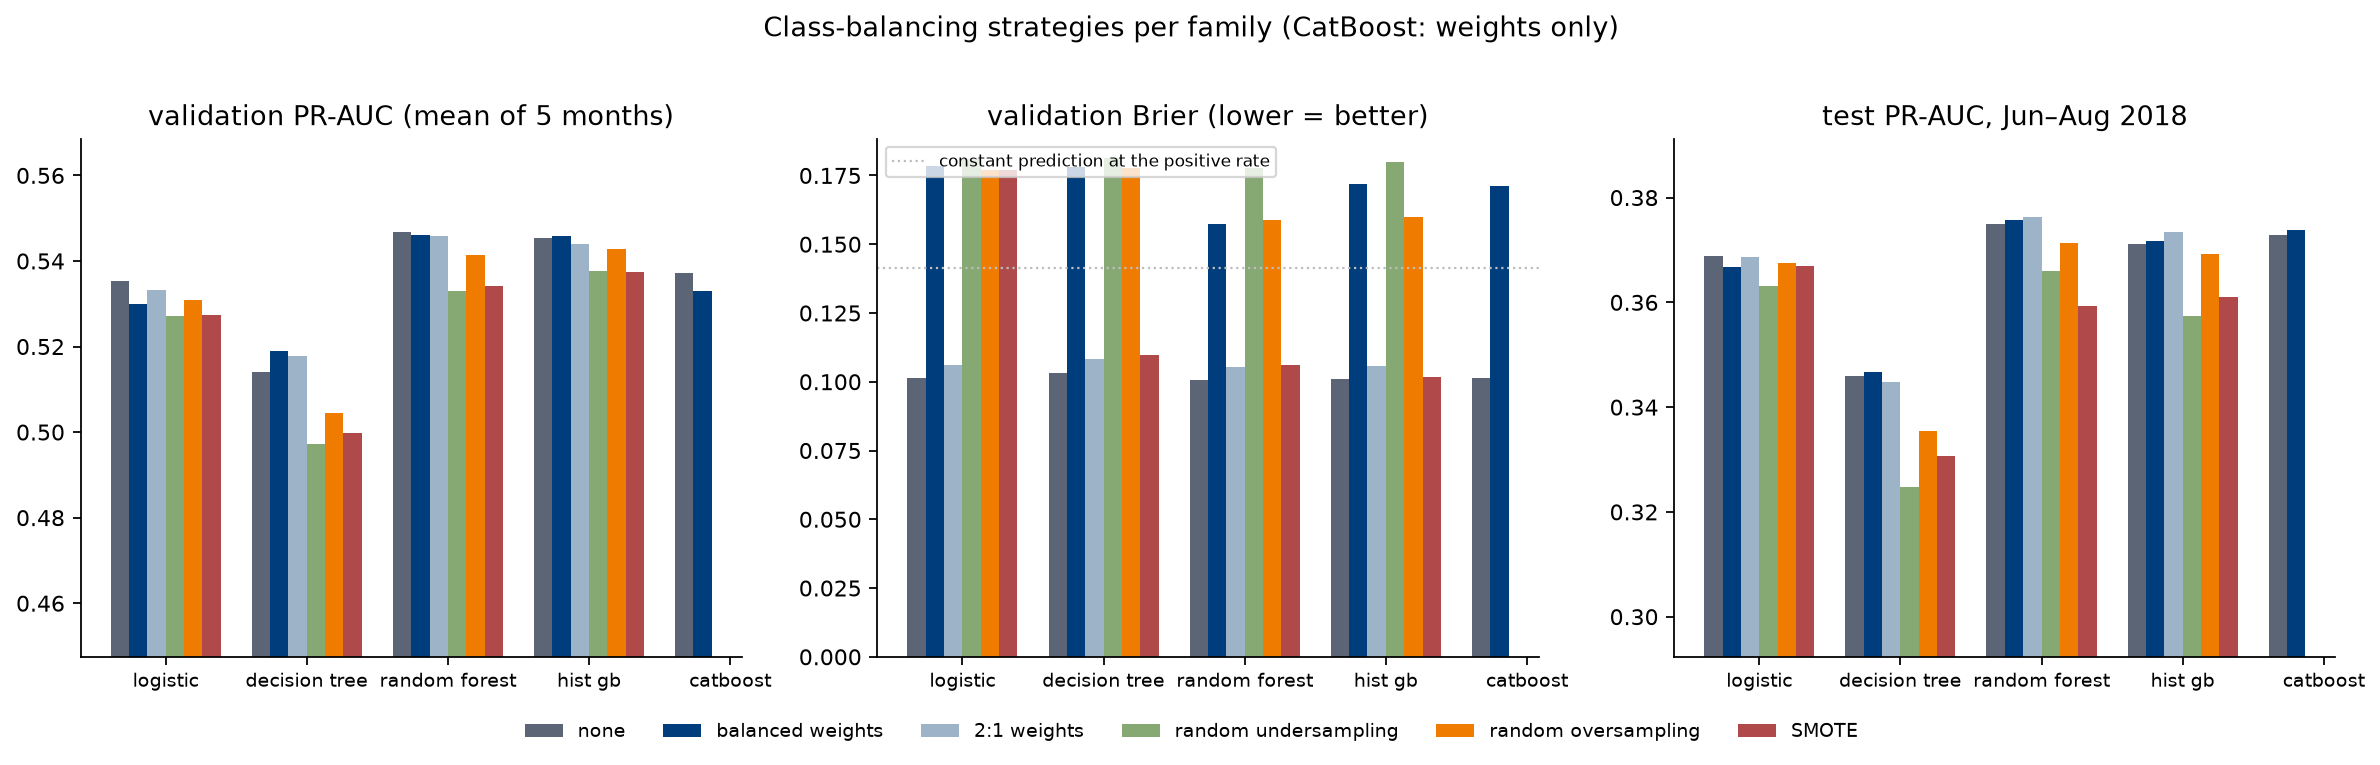

In [7]:
fig('E11_class_balance')

## 5. Stacking

One convex stack of the tuned logistic, random-forest and HGB models, the counterpart of the regression Ridge/RF/HGB stack. In each fold the weights (non-negative, summing to one, no intercept, minimising log loss) are fitted on base-model scores for the last three months inside that fold's training rows; the validation month is never used to fit them. Kept only if it beats the best single model by the feature rule. The test row is a secondary evaluation scored after the decision was saved.

bases                                                                               [logistic, random_forest, hist_gb]
best_single                                                                                              random_forest
rule                                   feature rule vs best single: +0.010 mean PR-AUC, better in >= 4/5 months, re...
meta_rule                              last 3 T-months inside each outer training frame; convex weights (>= 0, sum ...
base_configuration_scope               base hyperparameters were tuned on the same five validation months, so this ...
mean_val_pr_auc                                                                                                 0.5474
sd_val_pr_auc                                                                                                   0.0776
best_single_mean_val_pr_auc                                                                                     0.5468
pooled_oof_pr_auc                               

,fold,w_logistic,w_random_forest,w_hist_gb,meta_rows,meta_train_pr_auc,val_pr_auc,val_roc_auc,val_brier,val_recall_at_capacity,val_pr_auc_delivered_by_T,val_pr_auc_not_delivered_by_T
0,fold1,0.5032,0.4929,0.0039,9990,0.4235,0.4993,0.7751,0.0960,0.5879,0.2653,0.7540
1,fold2,0.4879,0.4820,0.0301,12869,0.5361,0.5460,0.7993,0.0967,0.6022,0.2656,0.7921
2,fold3,0.4856,0.4833,0.0311,14134,0.5521,0.6390,0.8464,0.1199,0.5725,0.3106,0.7273
3,fold4,0.4865,0.4873,0.0262,12897,0.5284,0.6055,0.8311,0.1037,0.6463,0.2767,0.7526
4,fold5,0.1862,0.7906,0.0232,14043,0.6200,0.4472,0.7778,0.0851,0.5842,0.2218,0.7032


,outer,inner_month,inner_train_rows,meta_rows,inner_train_last_T,meta_last_label,outer_cutoff,overlap
0,fold1,2017-10,21159,4522,2017-09-02 18:20:58,2017-12-31 06:29:04,2018-01-01,0
1,fold1,2017-11,25499,4686,2017-10-04 23:25:21,2017-12-27 22:38:55,2018-01-01,0
2,fold1,2017-12,29919,782,2017-11-03 23:52:52,2017-12-24 14:16:37,2018-01-01,0
3,fold2,2017-11,25499,4703,2017-10-04 23:25:21,2018-01-28 13:29:20,2018-02-01,0
4,fold2,2017-12,29919,7515,2017-11-03 23:52:52,2018-01-29 20:25:06,2018-02-01,0
5,fold2,2018-01,34984,651,2017-12-04 23:59:11,2018-01-30 22:59:04,2018-02-01,0
6,fold3,2017-12,29919,7526,2017-11-03 23:52:52,2018-02-28 23:45:10,2018-03-01,0
7,fold3,2018-01,34984,6338,2017-12-04 23:59:11,2018-02-27 12:52:28,2018-03-01,0
8,fold3,2018-02,42388,270,2018-01-04 23:48:32,2018-02-23 00:48:46,2018-03-01,0
9,fold4,2018-01,34984,6357,2017-12-04 23:59:11,2018-03-30 07:33:11,2018-04-01,0


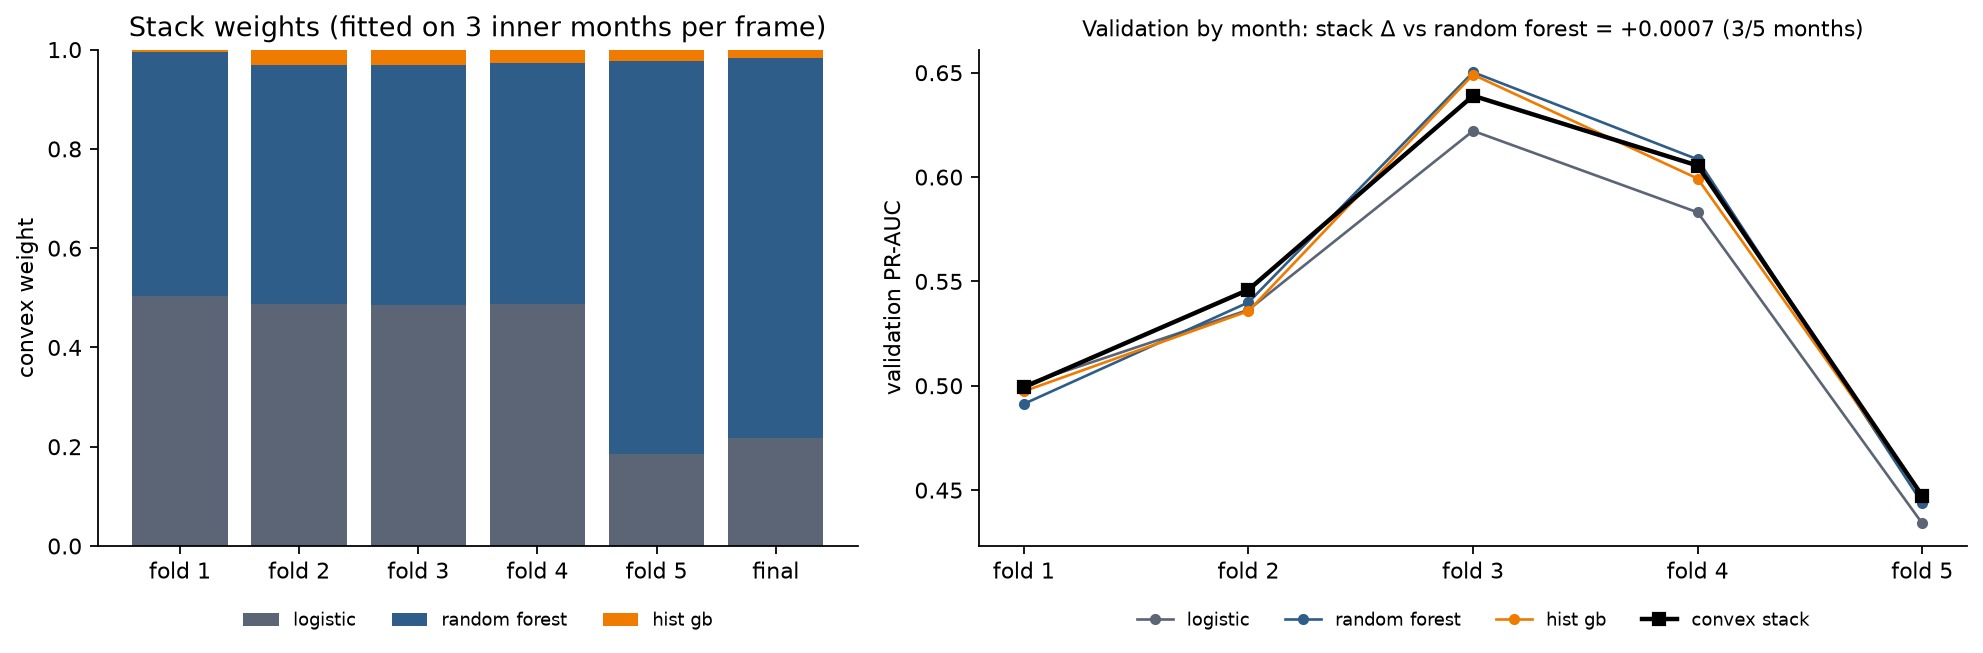

In [8]:
display(pd.Series(json.loads((EXP_DIR / 'stacking.json').read_text())))
display(t('stacking_folds')); display(t('stacking_inner_audit')); fig('E12_stacking')

## 6. Strict cut-off rerun

The v1 selection rerun with explicit availability rules from the quality audit: training labels answered before each cut-off (R1), validation labels answered before the 1 Jun selection date (R2), and features from approval / carrier events after T set to missing (R3). Same features, families, candidates and gap as v1. Written by `src/classification/run_strict_cutoff.py` to `outputs/classification/strict_cutoff/`. The test rows are retrospective: v1 had already used that window.

,fold,cutoff,train_rows_v1,train_rows_strict,removed_by_R1,removed_by_R1_low_review_rate,scored_rows_v1,scored_rows_strict,removed_by_R2,scored_low_review_rate_v1,scored_low_review_rate_strict,removed_by_R2_low_review_rate
0,fold1,2018-01-01,34984,34900,84,0.1310,6373,6370,3,0.1455,0.1455,0.0000
1,fold2,2018-02-01,42388,42315,73,0.1096,5936,5921,15,0.1541,0.1542,0.1333
2,fold3,2018-03-01,48380,48296,84,0.1429,7406,7390,16,0.2356,0.2359,0.1250
3,fold4,2018-04-01,54684,54595,89,0.1461,7547,7524,23,0.1862,0.1862,0.1739
4,fold5,2018-05-01,62205,62113,92,0.1087,7133,6768,365,0.1207,0.1155,0.2164
5,final,2018-06-01,70136,70054,82,0.1341,21058,21058,0,0.1126,0.1126,NaN


,setting,scored_rows,mean_val_pr_auc,mean_val_recall_at_capacity,mean_val_brier,d_pr_auc_vs_v1_rules,months_better,per_fold_d_pr,mean_train_rows,val_rows
0,v1 rules,labels known by 1 Jun (R2),0.5466,0.5913,0.1563,0.0000,0,+0.0000;+0.0000;+0.0000;+0.0000;+0.0000,48528.2,33973
1,v1 rules,all validation orders,0.5463,0.5934,0.1574,0.0000,0,+0.0000;+0.0000;+0.0000;+0.0000;+0.0000,48528.2,34395
2,R1 training labels only,labels known by 1 Jun (R2),0.5452,0.5935,0.1564,-0.0014,2,+0.0017;-0.0029;-0.0047;+0.0019;-0.0030,48443.8,33973
3,R1 training labels only,all validation orders,0.5448,0.5940,0.1575,-0.0015,2,+0.0017;-0.0031;-0.0048;+0.0017;-0.0029,48443.8,34395
4,R3 event masking only,labels known by 1 Jun (R2),0.5457,0.5934,0.1565,-0.0009,1,-0.0006;-0.0000;-0.0016;+0.0005;-0.0026,48528.2,33973
5,R3 event masking only,all validation orders,0.5455,0.5941,0.1576,-0.0008,1,-0.0006;-0.0002;-0.0016;+0.0005;-0.0021,48528.2,34395
6,strict (R1 + R3),labels known by 1 Jun (R2),0.5448,0.5933,0.1564,-0.0018,1,+0.0013;-0.0015;-0.0045;-0.0002;-0.0039,48443.8,33973
7,strict (R1 + R3),all validation orders,0.5446,0.5946,0.1575,-0.0017,1,+0.0013;-0.0018;-0.0046;-0.0003;-0.0032,48443.8,34395


,family,cv_pr_auc_mean,cv_pr_auc_sd,cv_recall_at_capacity_mean,train_pr_auc_mean,params,v1_cv_pr_auc_mean,same_params_as_v1
0,random_forest,0.5460,0.0863,0.5945,0.5525,"{""model__max_depth"": 22, ""model__max_features"": 0.21006520409256432, ""model_...",0.5463,False
1,catboost,0.5310,0.0755,0.5878,0.5358,"{""model__depth"": 4, ""model__iterations"": 1000, ""model__l2_leaf_reg"": 8.05645...",0.5317,True
2,logistic_tuned,0.5283,0.0772,0.5927,0.4738,"{""model__C"": 0.01}",0.5294,True
3,logistic_base,0.5266,0.0791,0.5915,0.4817,{},0.5278,True
4,decision_tree,0.5189,0.0820,0.5782,0.5023,"{""model__max_depth"": 12, ""model__min_samples_leaf"": 179}",0.5186,False
5,baseline_not_delivered_by_T,0.3822,0.0935,0.4952,NaN,{},0.3832,False
6,baseline_majority,0.1675,0.0458,0.2000,NaN,{},0.1684,False


setting
known-answer q99 (k=21)    0.5466
no gap (k=0), R1 only      0.5507
v1 gap (k=27) - main       0.5460
Name: val_pr_auc, dtype: float64

,model,split,pr_auc,roc_auc,brier,positive_rate,recall_at_capacity,precision_at_capacity,lift_at_capacity,n,train_pr_auc,train_rows
0,strict selection: random_forest,train (in-sample),0.5993,0.8731,0.1387,0.1514,0.6392,0.4838,3.1960,70054.0,NaN,NaN
1,strict selection: random_forest,CV mean (labels known by 1 Jun),0.5460,NaN,NaN,NaN,0.5945,NaN,NaN,NaN,NaN,NaN
2,strict selection: random_forest,test Jun-Aug 2018,0.3738,0.7397,0.1526,0.1126,0.5352,0.3013,2.6761,21058.0,NaN,NaN
3,"v1 forest, v1 rules (reproduced)",test Jun-Aug 2018 (secondary),0.3749,0.7392,0.1492,0.1126,0.5323,0.2996,2.6613,21058.0,0.6099,70136.0
4,"v1 forest, strict rules",test Jun-Aug 2018 (secondary),0.3746,0.7393,0.1494,0.1126,0.5306,0.2987,2.6529,21058.0,0.6104,70054.0
5,baseline_not_delivered_by_T,test Jun-Aug 2018,0.2099,0.6284,0.1245,0.1126,0.4057,0.2284,2.0287,21058.0,NaN,NaN
6,baseline_majority,test Jun-Aug 2018,0.1126,NaN,NaN,0.1126,0.2000,NaN,NaN,21058.0,NaN,NaN


,comparison,d_pr_auc,d_pr_auc_ci,d_recall,d_recall_ci
0,strict selection (random_forest) - v1,-0.0012,"[-0.00434997308247953, 0.0018233012310131984]",0.0030,"[-0.002570036372097936, 0.009040184893060244]"
1,v1 forest under strict rules - v1,-0.0003,"[-0.0018842769508764109, 0.0012673548576228265]",-0.0017,"[-0.005410242828504469, 0.0038395904436859833]"


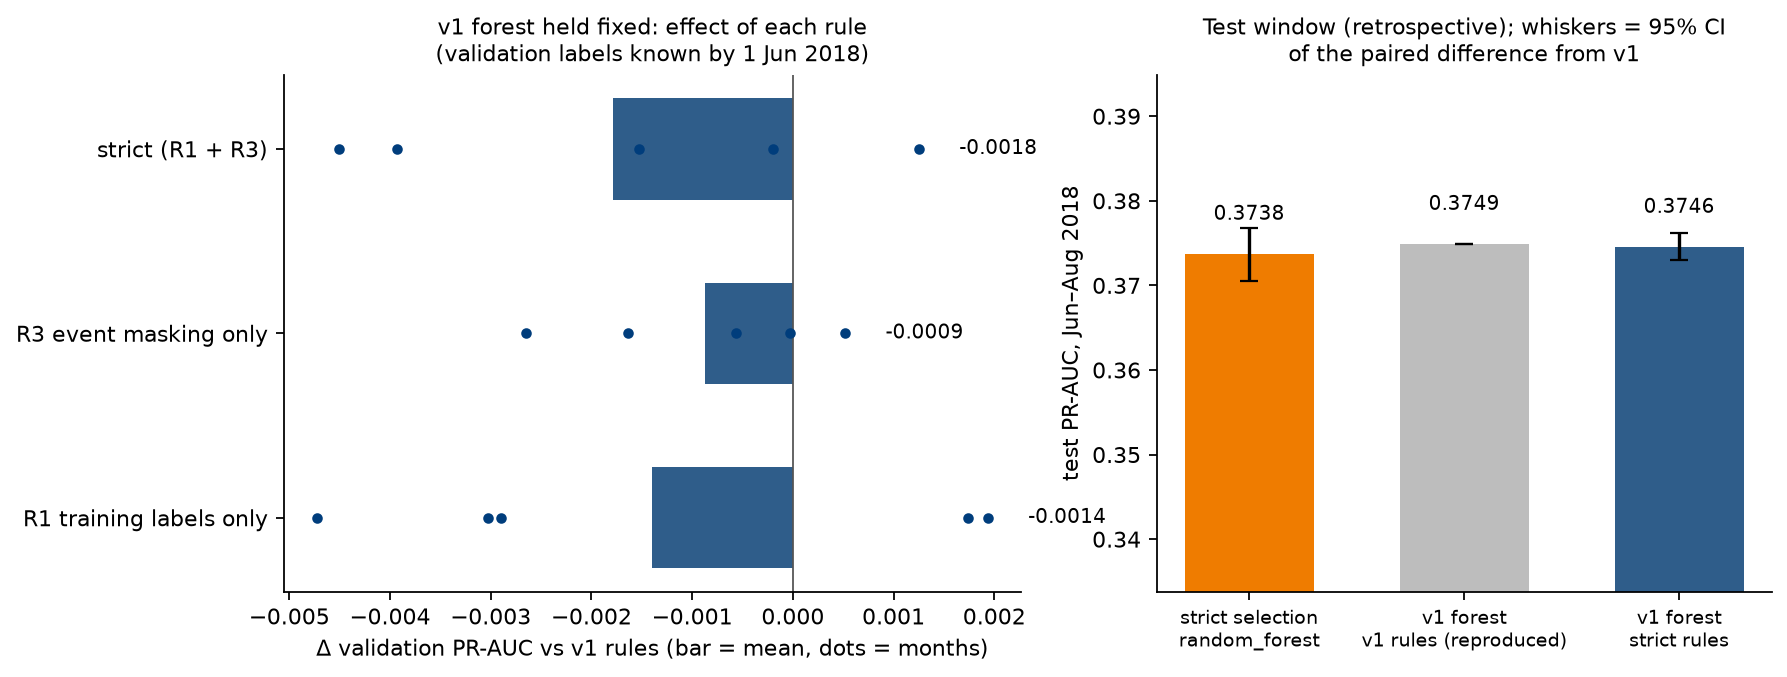

In [9]:
SC = V1_DIR / 'strict_cutoff'
sc = lambda n: pd.read_csv(SC / 'tables' / f'{n}.csv')
display(sc('strict_fold_table')); display(sc('diagnostic_rules'))
display(sc('cv_family_summary')); display(sc('gap_sensitivity').groupby('setting').val_pr_auc.mean())
display(sc('test_results')); display(sc('paired_bootstrap'))
display(Image(filename=str(SC / 'figures' / 'SC1_strict_cutoff.png')))

## 7. Hyperparameter tuning

Random forest and HGB: two-stage screened search (stage 1 on folds 3–5, stage 2 the best three on all folds). Logistic: C grid. Decision tree: 20 random candidates. CatBoost: v1 parameters.

,candidate,params,key,screen_pr_auc,seconds,full_pr_auc,family
0,8,"{""max_depth"": 30, ""max_features"": 0.1652047713392534, ""max_samples"": 0.56540...",b42d31227d6fb048,0.5692,42.5,0.5479,random_forest
1,3,"{""max_depth"": 22, ""max_features"": 0.5486570693415702, ""max_samples"": 0.91887...",8e69542f7b359437,0.5687,133.4,0.5480,random_forest
2,20,"{""max_depth"": 27, ""max_features"": 0.2406080559441889, ""max_samples"": 0.76935...",e3ec38e9bf5acd47,0.5687,96.6,0.5476,random_forest
3,2,"{""max_depth"": 20, ""max_features"": 0.3560730631510337, ""max_samples"": 0.96521...",05311c20506d02f2,0.5685,215.6,NaN,random_forest
4,7,"{""max_depth"": 8, ""max_features"": 0.2918368563085775, ""max_samples"": 0.811138...",bfd50f773d44a1d4,0.5684,56.8,NaN,random_forest
5,12,"{""max_depth"": 24, ""max_features"": 0.6466544763013522, ""max_samples"": 0.95049...",1fee09acf17030dd,0.5682,205.8,NaN,random_forest
6,14,"{""max_depth"": 10, ""max_features"": 0.6096024734753729, ""max_samples"": 0.74045...",718377c3858cd86c,0.5679,253.2,NaN,random_forest
7,6,"{""max_depth"": 19, ""max_features"": 0.2049815210642887, ""max_samples"": 0.91039...",7f9526a461529489,0.5678,59.2,NaN,random_forest


,candidate,params,key,screen_pr_auc,seconds,full_pr_auc,family
0,9,"{""l2_regularization"": 0.03680802181661672, ""learning_rate"": 0.02907784244415...",89b10a51dcf54a78,0.5656,26.5,0.5442,hist_gb
1,26,"{""l2_regularization"": 0.009920950864900802, ""learning_rate"": 0.0205046138023...",0a9c42988c33ae9f,0.5653,27.7,0.5458,hist_gb
2,21,"{""l2_regularization"": 0.08293587215701027, ""learning_rate"": 0.02321402787486...",72b45bee0d52b4dc,0.5649,29.0,0.5448,hist_gb
3,8,"{""l2_regularization"": 2.4039441941584023, ""learning_rate"": 0.047741601157768...",176366eac3f3a4ec,0.5648,24.5,NaN,hist_gb
4,7,"{""l2_regularization"": 0.013957303395178393, ""learning_rate"": 0.0423213069987...",4f662dc09f5198aa,0.5645,25.2,NaN,hist_gb
5,23,"{""l2_regularization"": 0.10787713598375757, ""learning_rate"": 0.04132306866919...",bc98711decb10129,0.5641,24.3,NaN,hist_gb
6,5,"{""l2_regularization"": 0.30839536290886865, ""learning_rate"": 0.02739988529234...",6d1e527f1b54cbf2,0.5639,24.8,NaN,hist_gb
7,20,"{""l2_regularization"": 0.002680426771873759, ""learning_rate"": 0.0239325599095...",7321f39ed7aeb54e,0.5639,29.3,NaN,hist_gb


,candidate,params,key,full_pr_auc,family
0,0,"{""C"": 0.001}",7cda537156270ff9,0.5331,logistic
1,1,"{""C"": 0.01}",ac0f4e32ae4507f3,0.5352,logistic
2,2,"{""C"": 0.1}",fba7d4e124bc24bc,0.5350,logistic
3,3,"{""C"": 1}",271fcabb5b37eaf7,0.5333,logistic
4,4,"{""C"": 10}",9bc1970f01e6d1d1,0.5329,logistic
5,5,"{""C"": 100}",e8fd5a6a4f42950d,0.5328,logistic
6,6,"{""C"": 1000}",6faa9eadca769f6f,0.5329,logistic


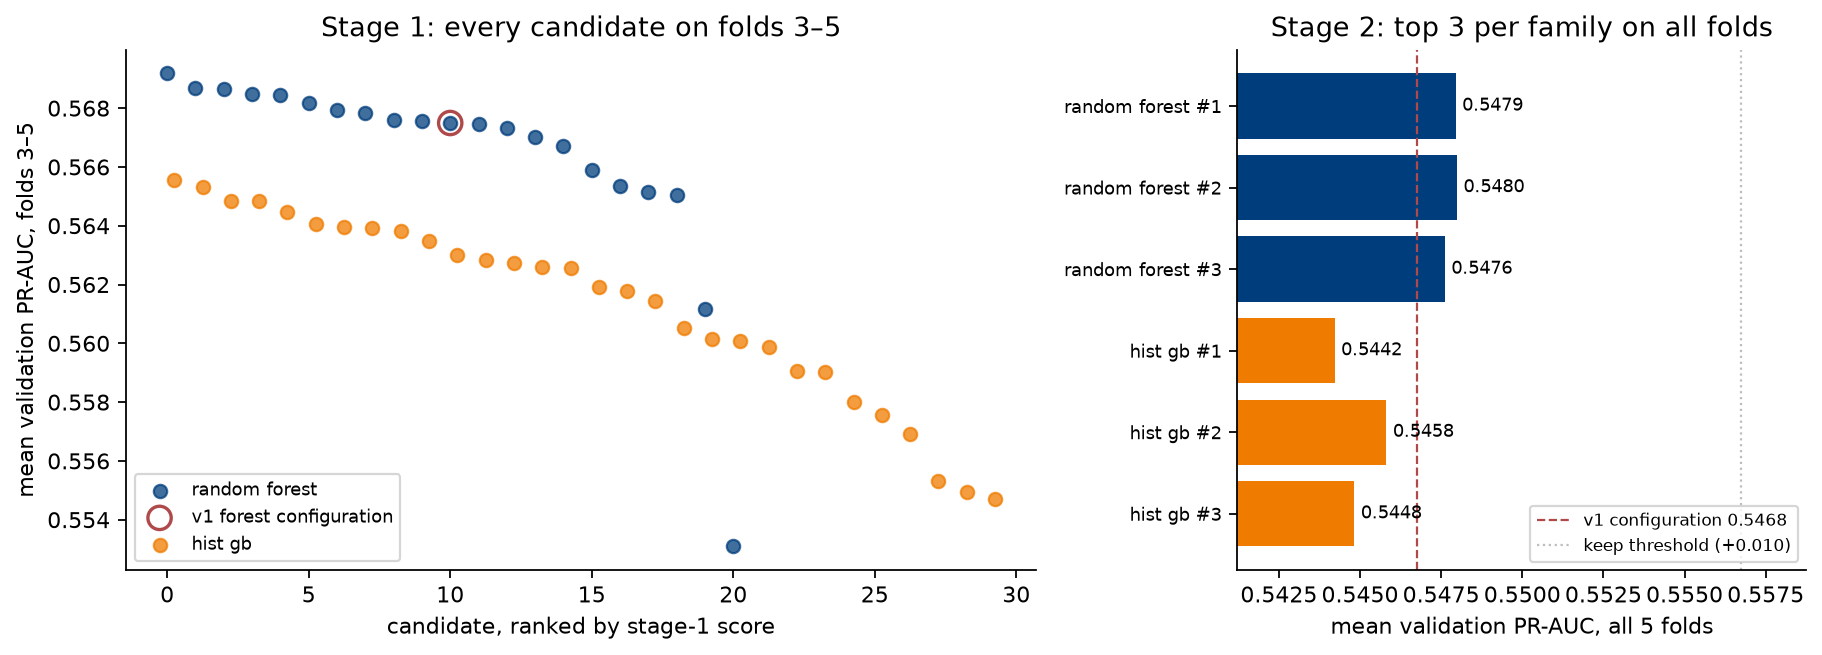

In [10]:
display(t('screened_search_random_forest').head(8)); display(t('screened_search_hist_gb').head(8))
display(t('search_logistic')); fig('E07_screened_search')

## 8. Train, each validation month, pooled validation and test, every family

In [11]:
pf = t('per_fold'); best = led[led.experiment.str.startswith('best ') | (led.step=='S0')]
pf[pf.key.isin(best.key)].pivot_table(index='experiment', columns='fold', values='val_pr_auc').round(4)

fold,fold1,fold2,fold3,fold4,fold5
experiment,,,,,
best catboost,0.4880,0.5309,0.6266,0.5760,0.4439
best decision_tree,0.4709,0.5199,0.6087,0.5808,0.4147
best hist_gb,0.4974,0.5358,0.6491,0.5993,0.4476
best logistic,0.5004,0.5364,0.6221,0.5831,0.4340
best random_forest,0.4913,0.5400,0.6502,0.6085,0.4438
forest: class weight none,0.4913,0.5400,0.6502,0.6085,0.4438
logistic: class weight none,0.5004,0.5364,0.6221,0.5831,0.4340
"v1 frozen forest, reproduced",0.4889,0.5407,0.6471,0.6074,0.4473
v2 = random_forest vs v1,0.4913,0.5400,0.6502,0.6085,0.4438


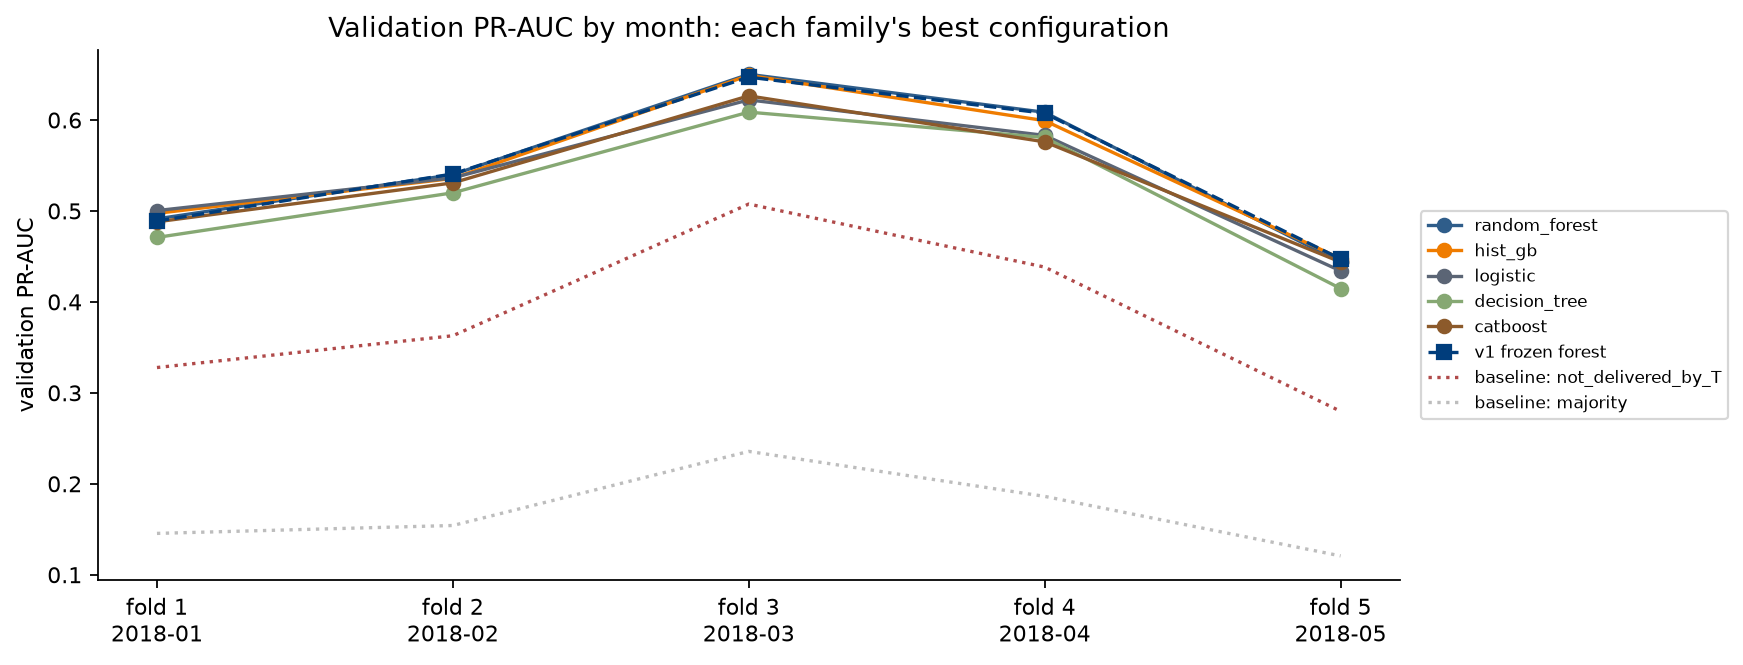

,model,is_v2,variant,train_pr_auc,pooled_oof_pr_auc,pooled_oof_roc_auc,pooled_oof_brier,pooled_oof_recall_at_capacity,test_pr_auc,test_roc_auc,test_brier,test_recall_at_capacity,test_pr_auc_delivered_by_T,test_pr_auc_not_delivered_by_T,train_rows,seconds
0,random_forest,True,"random_forest, late=calendar, cw=none",0.6040,0.5673,0.8156,0.1009,0.6289,0.3750,0.7397,0.0883,0.5335,0.1964,0.6436,70136.0,80.0
1,hist_gb,False,"hist_gb, late=calendar, cw=balanced",0.5695,0.5675,0.8134,0.1719,0.6316,0.3717,0.7408,0.1606,0.5335,0.1980,0.6427,70136.0,12.0
2,logistic,False,"logistic, late=calendar, cw=none",0.5255,0.5539,0.8142,0.1018,0.6255,0.3689,0.7377,0.0880,0.5361,0.1938,0.6411,70136.0,3.0
3,decision_tree,False,"decision_tree, late=calendar, cw=balanced",0.5475,0.5471,0.8076,0.1785,0.6169,0.3466,0.7282,0.1628,0.5335,0.1808,0.5899,70136.0,4.0
4,catboost,False,"catboost, late=calendar, cw=balanced",0.5716,0.5537,0.8096,0.1712,0.6250,0.3738,0.7398,0.1558,0.5373,0.1978,0.6457,70136.0,163.0
5,v1 frozen forest (headline),False,frozen selection 44802a8d,NaN,NaN,NaN,NaN,NaN,0.3749,0.7392,0.1492,0.5323,0.1956,0.6451,NaN,NaN
6,baseline: not delivered by T,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2099,0.6284,NaN,0.4057,NaN,NaN,NaN,NaN
7,baseline: no skill,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1126,NaN,NaN,0.2000,NaN,NaN,NaN,NaN


In [12]:
fig('E05_validation_by_month'); t('test_results_v2')

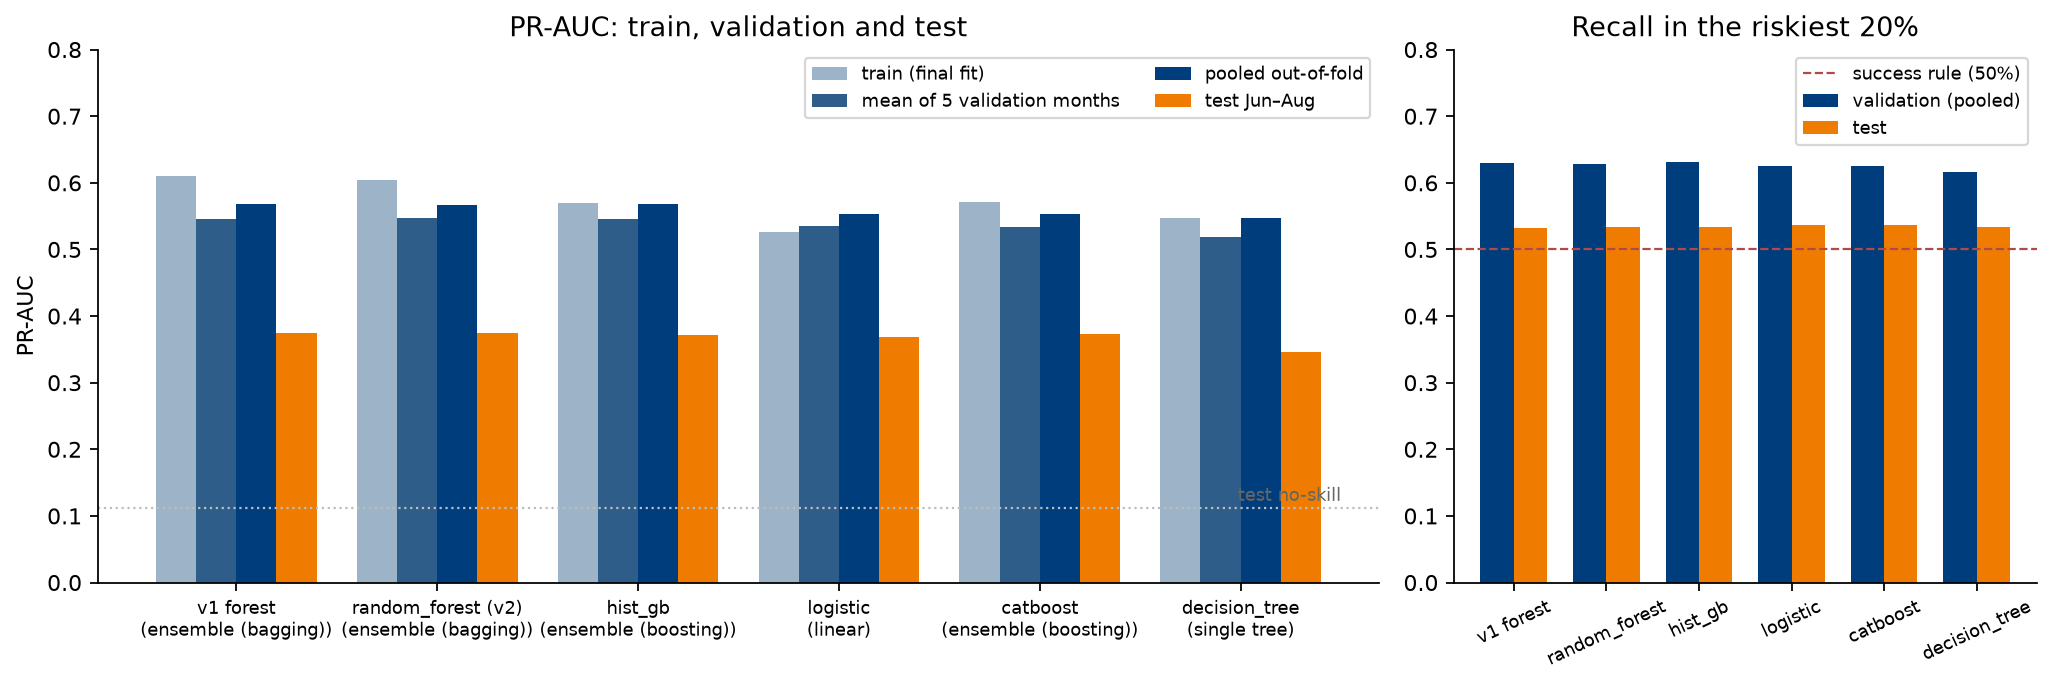

,metric,v1,v2,difference,ci_low,ci_high
0,PR-AUC,0.3749,0.3750,2.7619e-05,-0.0016,0.0017
1,recall in top 20%,0.5323,0.5335,1.2653e-03,-0.0029,0.0063


In [13]:
fig('E06_train_validation_test'); t('paired_bootstrap_v2_vs_v1')

## 9. Orders delivered by T

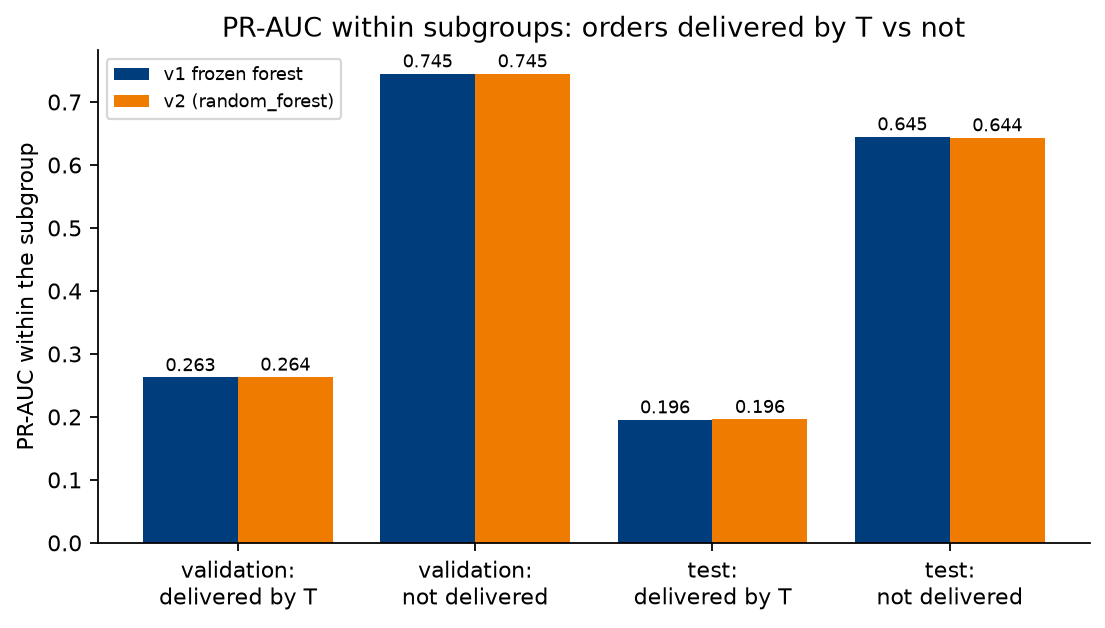

In [14]:
fig('E10_subgroups')

## 10. Calibration and daily capacity

,model,fold,raw_brier,constant_brier,raw_pr_auc,sigmoid_brier,sigmoid_pr_auc,isotonic_brier,isotonic_pr_auc
0,v1,fold2,0.1527,0.1305,0.5407,0.0964,0.5407,0.0971,0.5096
1,v1,fold3,0.1735,0.1875,0.6471,0.1184,0.6471,0.1183,0.6281
2,v1,fold4,0.1622,0.1515,0.6074,0.1045,0.6074,0.1041,0.5940
3,v1,fold5,0.1432,0.1100,0.4473,0.0863,0.4473,0.0860,0.4347
4,v2,fold2,0.0970,0.1305,0.5400,0.0975,0.5400,0.0975,0.5015
5,v2,fold3,0.1199,0.1875,0.6502,0.1194,0.6502,0.1181,0.6340
6,v2,fold4,0.1038,0.1515,0.6085,0.1043,0.6085,0.1042,0.5960
7,v2,fold5,0.0852,0.1100,0.4438,0.0867,0.4438,0.0872,0.4320


,model,method,months_better,mean_raw_brier,mean_calibrated_brier,mean_d_pr_auc,decision
0,v1,sigmoid,4,0.1579,0.1014,0.0000,keep
1,v1,isotonic,4,0.1579,0.1014,-0.0190,reject
2,v2,sigmoid,1,0.1015,0.1020,0.0000,reject
3,v2,isotonic,1,0.1015,0.1018,-0.0197,reject


,model,test_raw_brier,test_sigmoid_brier,test_constant_brier_at_validation_rate,test_pr_auc_raw,test_pr_auc_sigmoid
0,v1,0.1492,0.0900,0.1032,0.3749,0.3749
1,v2,0.0883,0.0905,0.1032,0.3750,0.3750


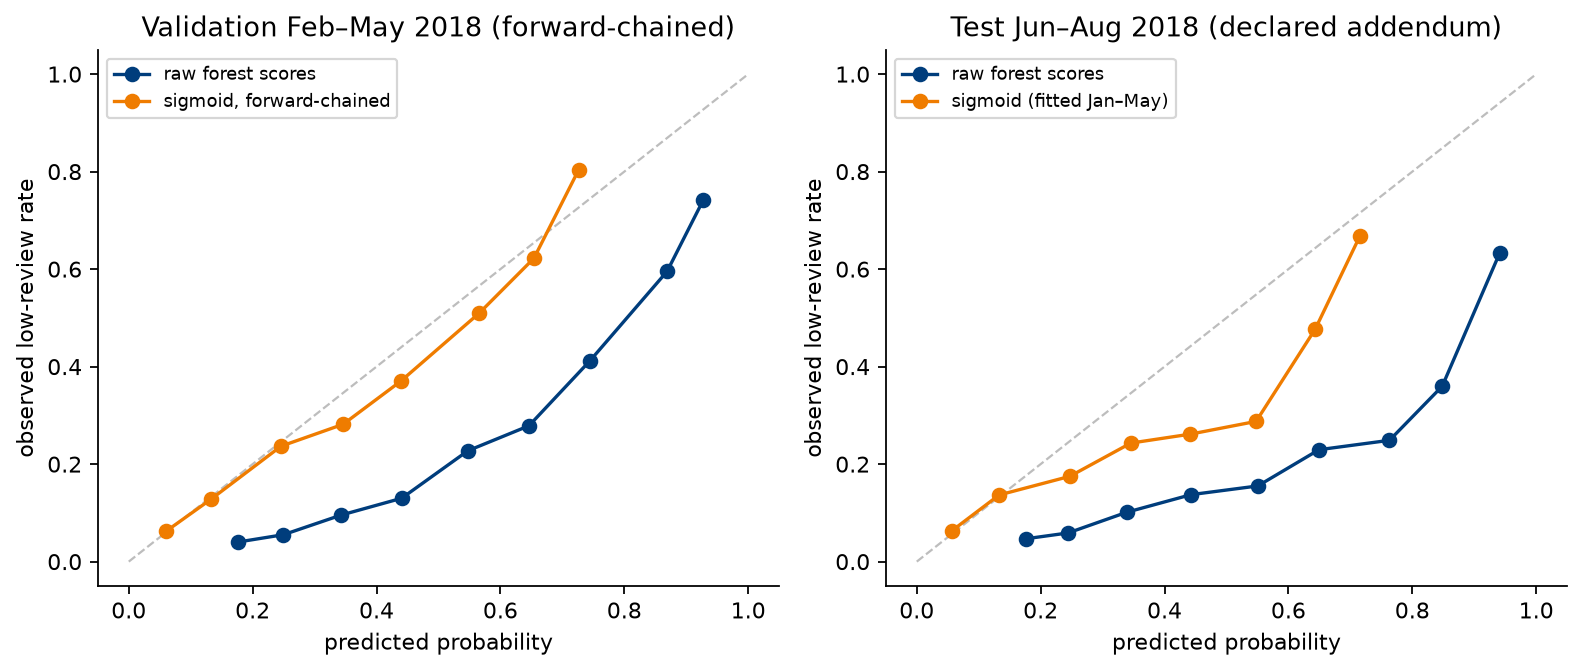

In [15]:
display(t('calibration_forward')); display(t('calibration_decisions')); display(t('calibration_test_addendum'))
fig('E08_reliability')

In [16]:
t('daily_batch_recall')

,model,window,pooled_daily_recall,window_recall,days,orders
0,v1,validation Jan-May 2018,0.5665,0.6301,150,34395
1,v2,validation Jan-May 2018,0.5665,0.6289,150,34395
2,v1,test Jun-Aug 2018,0.5175,0.5323,92,21058
3,v2,test Jun-Aug 2018,0.5150,0.5335,92,21058


## 11. What the model relies on

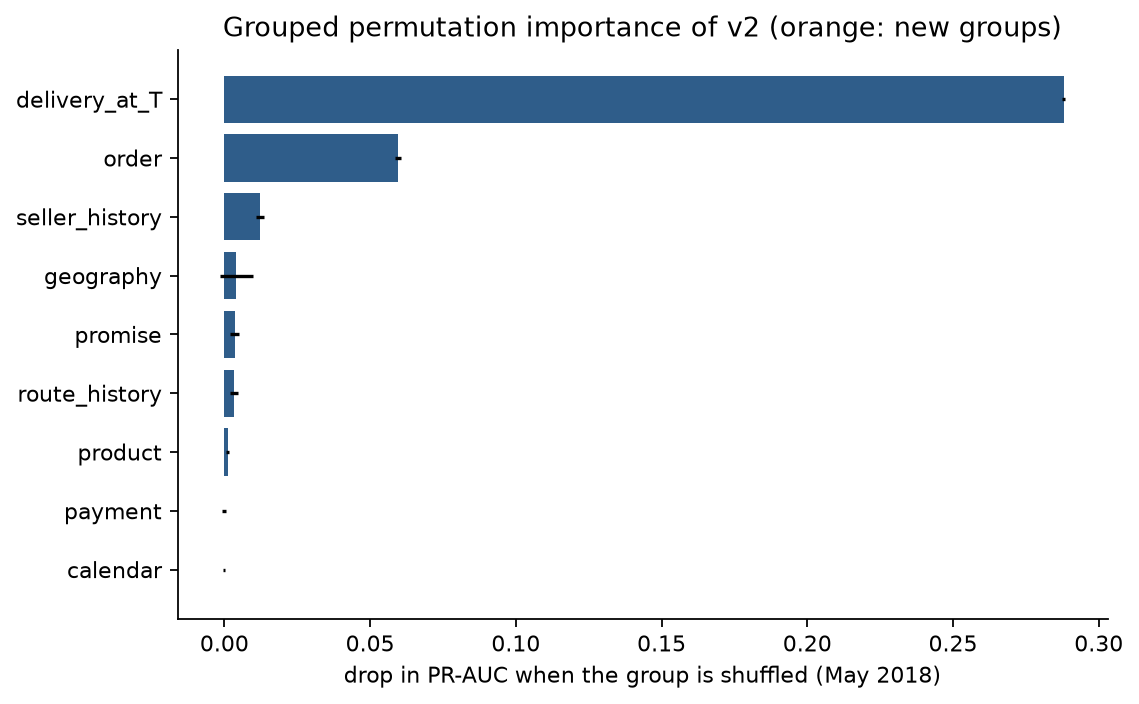

,group,features,drop_mean,drop_sd
0,delivery_at_T,9,2.8801e-01,0.0005
1,order,7,5.9525e-02,0.0010
2,seller_history,6,1.2197e-02,0.0015
3,geography,9,4.1168e-03,0.0057
4,promise,3,3.5199e-03,0.0014
5,route_history,3,3.2925e-03,0.0014
6,product,6,1.0749e-03,0.0007
7,payment,4,-2.0599e-05,0.0006
8,calendar,4,-2.6546e-05,0.0003


In [17]:
fig('E09_importance_v2'); t('importance_groups_v2')

In [18]:
sel = json.loads((EXP_DIR / 'selection_v2.json').read_text())
Markdown(f"**v2 family:** {sel['v2_family']}  \n**Recommended over v1 by the agreed rule:** {sel['recommended']}")

**v2 family:** random_forest  
**Recommended over v1 by the agreed rule:** False